#   EDA — Detección de Drift
## Caso: Planta de Flotación Minera (Predicción de Impurezas)

Este notebook aborda la **Fase 1 (EDA)** de un proyecto de Machine Learning aplicado a un proceso industrial continuo (Minería). El foco está puesto en el análisis univariado/multivariado, el manejo de series de tiempo con distintas frecuencias, la **detección crítica de fuga de datos** y la justificación de por qué el monitoreo de drift importa en este caso de negocio.
https://www.kaggle.com/datasets/edumagalhaes/quality-prediction-in-a-mining-process

## Contexto del Caso de Negocio

En el proceso de beneficio de mineral de hierro, una planta de flotación necesita predecir la cantidad de **sílice (impureza)** presente en el concentrado final. Actualmente, estas mediciones de laboratorio se obtienen cada hora.

**Objetivo del Modelo:**
Predecir el porcentaje de sílice con antelación utilizando datos de los sensores de la planta (flujos, niveles de aire, calidad de entrada) muestreados cada 20 segundos. Esto permite a los ingenieros de planta tomar decisiones tempranas y acciones correctivas para reducir impurezas y minimizar el mineral enviado a relaves (desechos).

**¿Por qué el Drift es relevante acá?**
En un entorno industrial a lo largo de 6 meses (marzo a septiembre de 2017), el modelo se enfrenta a múltiples fuentes de cambio continuo (*Concept y Data Drift*):
- **Cambios en la materia prima:** La veta del mineral extraído de la mina cambia sus propiedades geoquímicas con el tiempo.
- **Degradación de sensores:** Los sensores industriales que miden flujo y nivel sufren desgaste o descalibración temporal.
- **Intervenciones operativas:** Mantenimientos o cambios en las políticas de control de la planta.
Un modelo entrenado con datos de marzo inevitablemente se degradará para septiembre si las condiciones físicas y operativas cambian.

## Objetivos Críticos de este EDA
1. **Alineación Temporal:** Manejar la discrepancia entre variables de proceso (cada 20s) y variables objetivo (cada 1 hora).
2. **Prevención de Data Leakage:** Identificar y separar variables de laboratorio que ocurren simultáneamente con la variable objetivo.
3. **Baseline de Distribuciones:** Entender el comportamiento de la planta en los primeros meses para compararlo con los meses finales (simulación de producción).

# PASO 1: CONFIGURACIÓN INICIAL E IMPORTACIONES

In [ ]:
# ==============================================================================
# PASO 1: CONFIGURACIÓN INICIAL E IMPORTACIONES
# ==============================================================================

import sys
import pathlib
import requests

# 1. Detección del entorno de ejecución
# Esto es útil para saber si estamos corriendo en la nube (Google Colab) o en local.
IN_COLAB = "google.colab" in sys.modules
print("Corriendo en Colab:", IN_COLAB)

# 2. Instalación de dependencias (Opcional)
# Si ejecutas en Colab y necesitas asegurar versiones, descomenta las siguientes líneas.
# Se agregó 'gdown' para la descarga desde Google Drive en el Paso 2.
# %%capture
# !pip install -q "pandas>=2.0" "pyarrow>=14" "numpy>=1.26" matplotlib seaborn requests gdown

# 3. Importación de librerías principales con validación
print("Importando dependencias...")
try:
    import matplotlib.pyplot as plt  # Para creación de gráficos base
    import numpy as np               # Para operaciones matemáticas y manejo de arrays
    import pandas as pd              # Para manipulación y análisis de datos tabulares
    import seaborn as sns            # Para visualizaciones estadísticas más atractivas
    import pyarrow as pa             # Core de Apache Arrow
    import pyarrow.parquet as pq     # Para leer metadatos y archivos Parquet
    import gdown                     # Para descargar el dataset desde Google Drive

    # Confirmación visual de que todo se instaló e importó con éxito
    print("✅ Todas las dependencias se instalaron e importaron correctamente.")
    print(f"   - Pandas versión: {pd.__version__}")
    print(f"   - Numpy versión: {np.__version__}")
    print(f"   - Seaborn versión: {sns.__version__}")
    print(f"   - PyArrow versión: {pa.__version__}")
    print(f"   - Gdown versión: {gdown.__version__}")

except ImportError as e:
    # Si alguna librería no está instalada, mostramos un error claro y detenemos el script
    print(f"❌ Error crítico al importar dependencias: {e}")
    print("Por favor, asegúrate de instalar los paquetes necesarios antes de continuar.")
    raise  # Detiene la ejecución de la celda

# 4. Configuración visual y de visualización de datos
# Establecemos un estilo limpio y profesional para todos los gráficos de Seaborn
sns.set_theme(style="whitegrid")

# Configuramos Pandas para poder ver hasta 50 columnas al imprimir un DataFrame
pd.set_option("display.max_columns", 50)

# 5. Configuración de rutas del proyecto
# Creamos una carpeta específica para los datos de la planta
DATA_DIR = pathlib.Path("data_flotacion")

# Creamos el directorio si no existe. 'exist_ok=True' evita errores si ya estaba creada.
DATA_DIR.mkdir(exist_ok=True)

# 6. Definición de constantes globales
# Fijar una semilla aleatoria garantiza que los resultados sean reproducibles
RANDOM_STATE = 42

# Definimos el tamaño de la muestra. Ideal para testear rápido durante el EDA.
SAMPLE_SIZE = 40_000

Corriendo en Colab: True
Importando dependencias...
✅ Todas las dependencias se instalaron e importaron correctamente.
   - Pandas versión: 2.2.3
   - Numpy versión: 2.1.3
   - Seaborn versión: 0.13.2
   - PyArrow versión: 18.1.0
   - Gdown versión: 5.2.2


# PASO 2: DESCARGA E INGESTA DE DATOS

In [ ]:
# ==============================================================================
# PASO 2: DESCARGA E INGESTA DE DATOS
# ==============================================================================

# ID del archivo de Google Drive (Datos de la Planta de Flotación)
FILE_ID = "1mj3P2IXmVPkC7QfVf-Cp-nb3XGHCQKI7"

# Definimos la ruta donde se guardará el archivo usando DATA_DIR del Paso 1
OUTPUT_FILE = DATA_DIR / "dataset_flotacion.csv"

# Comprobamos si el archivo ya existe para no descargarlo múltiples veces
if not OUTPUT_FILE.exists():
    print(f"Descargando archivo desde Google Drive a la carpeta '{DATA_DIR}'...")
    # gdown requiere que la ruta sea un string
    gdown.download(id=FILE_ID, output=str(OUTPUT_FILE), quiet=False)
    print("✅ Archivo descargado correctamente.")
else:
    print(f"✅ El archivo ya existe en '{OUTPUT_FILE}'. Omitiendo descarga.")

print("\nCargando dataset en memoria (esto puede tomar unos segundos)...")
# Cargamos el archivo CSV en un DataFrame de pandas.
# low_memory=False evita que pandas intente adivinar tipos de datos por fragmentos,
# lo cual previene advertencias y errores en datasets industriales grandes.
df = pd.read_csv(OUTPUT_FILE, low_memory=False)

# Imprimimos la forma del dataset para confirmar que todo cargó bien
print("✅ Dataset cargado con éxito.")
print(f"   - Filas originales: {df.shape[0]:,}")
print(f"   - Columnas originales: {df.shape[1]:,}")

✅ El archivo ya existe en 'data_flotacion/dataset_flotacion.csv'. Omitiendo descarga.

Cargando dataset en memoria (esto puede tomar unos segundos)...
✅ Dataset cargado con éxito.
   - Filas originales: 737,453
   - Columnas originales: 24


# PASO 3: ANÁLISIS DE VOLUMEN Y TENDENCIA MACRO (GRÁFICO 1)

Analizando volumen de datos por mes...


,n_registros
mes,
Marzo,37614
Abril,129599
Mayo,133920
Junio,129600
Julio,133920
Agosto,133920
Septiembre,38880


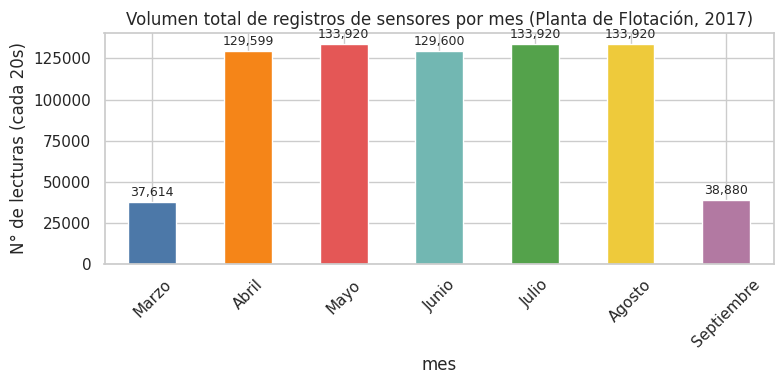

In [ ]:
# ==============================================================================
# PASO 3: ANÁLISIS DE VOLUMEN Y TENDENCIA MACRO (GRÁFICO 1)
# ==============================================================================

# Para poder contar por mes, primero necesitamos limpiar temporalmente los nombres
# de las columnas por si la columna de fecha viene con espacios o mayúsculas.
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Verificamos si existe la columna de fecha (usualmente 'date')
if 'date' in df.columns:
    print("Analizando volumen de datos por mes...")

    # Creamos columnas temporales para el análisis visual
    df['date_temp'] = pd.to_datetime(df['date'], errors='coerce')
    df['mes'] = df['date_temp'].dt.month

    # Conteo TOTAL de registros (lecturas de sensores) por mes
    volumen_total = df['mes'].value_counts().sort_index()

    # Mapeamos los números a nombres de meses (basado en tus datos de Mar a Sep 2017)
    meses_nombres = {3: "Marzo", 4: "Abril", 5: "Mayo", 6: "Junio", 7: "Julio", 8: "Agosto", 9: "Septiembre"}

    volumen_df = volumen_total.to_frame(name="n_registros")
    volumen_df.index = volumen_df.index.map(meses_nombres)
    display(volumen_df)

    # --- GRÁFICO : Volumen total de registros por mes ---
    fig, ax = plt.subplots(figsize=(8, 4))
    volumen_df["n_registros"].plot(
        kind="bar",
        ax=ax,
        color=["#4C78A8", "#F58518", "#E45756", "#72B7B2", "#54A24B", "#EECA3B", "#B279A2"]
    )

    ax.set_title("Volumen total de registros de sensores por mes (Planta de Flotación, 2017)")
    ax.set_ylabel("N° de lecturas (cada 20s)")
    plt.xticks(rotation=45)

    # Agregamos las etiquetas de datos sobre cada barra
    for i, v in enumerate(volumen_df["n_registros"]):
        ax.text(i, v + 2000, f"{v:,}", ha="center", va="bottom", fontsize=9)

    plt.tight_layout()
    plt.show()

    # Limpiamos las columnas temporales para no ensuciar el dataset para el Paso 4
    df.drop(columns=['date_temp', 'mes'], inplace=True)
else:
    print("⚠️ No se encontró la columna 'date' en el dataset original.")

## Interpretación del Volumen de Registros

1. **Meses estables (abril a agosto):** El volumen de datos se mantiene alto y constante, con aproximadamente **130.000 a 134.000 lecturas mensuales**. Esto indica una operación continua y un muestreo consistente de aproximadamente **20 segundos**.

2. **Meses incompletos (marzo y septiembre):** Se observa una disminución significativa en los registros, con aproximadamente **37.000 a 38.000 lecturas**. Esta reducción no necesariamente indica fallas en la captura de datos, sino que corresponde a **periodos parciales**, ya que la recolección comenzó a mediados de marzo y finalizó a principios de septiembre.

### Conclusión

La captura de datos de los sensores presenta un comportamiento **confiable y consistente durante la mayor parte del periodo analizado**. Sin embargo, al comparar los totales absolutos de registros entre meses, se debe considerar que **marzo y septiembre no corresponden a meses completos**, por lo que su menor volumen de datos es esperable.


# PASO 4: AUDITORÍA, LIMPIEZA Y ALINEACIÓN TEMPORAL (RESAMPLING)

In [ ]:
# ==============================================================================
# PASO 4.1: CARGA DE MUESTRA (REFERENCIA)
# ==============================================================================

# Limpieza rápida de nombres de columnas por si no se hizo previamente
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

def cargar_muestra(period: str, df_origen: pd.DataFrame, n=SAMPLE_SIZE) -> pd.DataFrame:
    """
    Filtra el dataset completo para extraer un mes específico.
    period: formato 'YYYY-MM', ej: '2017-03'
    """
    df_temp = df_origen.copy()

    # 1. Aseguramos que la columna de fecha sea tipo datetime
    df_temp['date'] = pd.to_datetime(df_temp['date'], errors='coerce')

    # 2. Extraemos el año y mes del string solicitado (ej: '2017-03' -> y=2017, m=3)
    y, m = int(period[:4]), int(period[5:7])

    # 3. Filtro exacto de fecha para el mes correspondiente
    mask = (df_temp["date"].dt.year == y) & (df_temp["date"].dt.month == m)
    df_mes = df_temp[mask].copy()

    # 4. Muestreo (si el mes tiene demasiadas filas para EDA)
    if len(df_mes) > n:
        df_mes = df_mes.sample(n=n, random_state=RANDOM_STATE)

    # 5. ORDEN CRONOLÓGICO: Si hubo muestreo aleatorio, el orden se rompió.
    # En series de tiempo industriales debemos restaurarlo antes de retornar.
    return df_mes.sort_values(by='date').reset_index(drop=True)


# El mes de referencia (pre-drift) para la planta minera es Marzo de 2017
ref = cargar_muestra("2017-03", df)

print("Muestra de referencia (Marzo 2017):", ref.shape)
display(ref.head())

Muestra de referencia (Marzo 2017): (37614, 24)


,date,%_iron_feed,%_silica_feed,starch_flow,amina_flow,ore_pulp_flow,ore_pulp_ph,ore_pulp_density,flotation_column_01_air_flow,flotation_column_02_air_flow,flotation_column_03_air_flow,flotation_column_04_air_flow,flotation_column_05_air_flow,flotation_column_06_air_flow,flotation_column_07_air_flow,flotation_column_01_level,flotation_column_02_level,flotation_column_03_level,flotation_column_04_level,flotation_column_05_level,flotation_column_06_level,flotation_column_07_level,%_iron_concentrate,%_silica_concentrate
0,2017-03-10 01:00:00,"55,2","16,98","3019,53","557,434","395,713","10,0664","1,74","249,214","253,235","250,576","295,096","306,4","250,225","250,884","457,396","432,962","424,954","443,558","502,255","446,37","523,344","66,91","1,31"
1,2017-03-10 01:00:00,"55,2","16,98","3185,55","586,182","404,648","10,1139","1,73614","250,488","250,488","249,214","295,096","306,4","250,137","248,95","450,139","510,332","461,638","422,888","451,528","510,098","513,904","66,91","1,31"
2,2017-03-10 01:00:00,"55,2","16,98","3182,03","595,947","407,168","10,1135","1,73545","250,62","252,334","249,39","295,096","306,4","256,465","251,499","440,53","518,6","465,414","405,704","433,686","513,794","512,252","66,91","1,31"
3,2017-03-10 01:00:00,"55,2","16,98","3180,86","600,464","402,598","10,113","1,73476","250,576","250,62","249,258","295,096","306,4","250,137","250,269","443,833","510,446","456,246","415,706","428,618","481,874","468,224","66,91","1,31"
4,2017-03-10 01:00:00,"55,2","16,98","1272,66","594,971","393,516","10,1125","1,73407","250,488","249,302","249,302","295,096","306,4","247,983","248,511","453,242","502,968","451,604","441,878","427,296","433,372","412,824","66,91","1,31"


## PASO 4.2: ESTRUCTURA GENERAL, NULOS Y ANOMALÍAS

In [ ]:
# ==============================================================================
# PASO 4.2: ESTRUCTURA GENERAL, NULOS Y ANOMALÍAS
# ==============================================================================

# 1. Corrección rápida de formatos
# (Convertimos comas a puntos para poder evaluar anomalías numéricamente)
for col in ref.columns:
    if ref[col].dtype == 'object' and col != 'date':
        try:
            ref[col] = ref[col].str.replace(',', '.').astype(float)
        except Exception:
            pass

# Limpieza adicional de nombres de columnas por si quedó algún símbolo
ref.columns = (
    ref.columns.str.replace('%', 'pct')
    .str.replace(',', '')
    .str.replace(r'\(|\)', '', regex=True)
)

ref.info()

print("\nNulos por columna:")
nulos = ref.isna().sum()
print(nulos[nulos > 0])
print()

n = len(ref)

# 2. Definición de anomalías (Reglas de negocio de la planta minera)
# Ajustamos la lógica al contexto físico de los sensores
anomalias = {
    "Flujos de reactivo negativos (amina_flow < 0)": (ref["amina_flow"] < 0).sum(),
    "Porcentaje de mineral fuera de rango (<0% o >100%)": ((ref["pct_iron_feed"] < 0) | (ref["pct_iron_feed"] > 100)).sum(),
    "Nivel de columna/tanque negativo": (ref["flotation_column_01_level"] < 0).sum(),
    "Flujo de pulpa en cero (ore_pulp_flow == 0)": (ref["ore_pulp_flow"] == 0).sum(),
    "Target (Sílice) nulo o faltante": ref["pct_silica_concentrate"].isna().sum()
}

print("Evaluación de anomalías operativas:")
for k, v in anomalias.items():
    print(f"{k}: {v} ({v/n:.2%})")

# Opcional: Revisar visualmente un par de casos anómalos si existen
ejemplos_raros = ref[(ref["ore_pulp_flow"] == 0) & (ref["pct_silica_concentrate"] > 0)]
if not ejemplos_raros.empty:
    print("\nAlerta: Se detectó Sílice a pesar de que el flujo de pulpa es 0 (posible error de sensor):")
    display(ejemplos_raros[["date", "ore_pulp_flow", "pct_silica_concentrate"]].head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37614 entries, 0 to 37613
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   date                          37614 non-null  datetime64[ns]
 1   pct_iron_feed                 37614 non-null  float64       
 2   pct_silica_feed               37614 non-null  float64       
 3   starch_flow                   37614 non-null  float64       
 4   amina_flow                    37614 non-null  float64       
 5   ore_pulp_flow                 37614 non-null  float64       
 6   ore_pulp_ph                   37614 non-null  float64       
 7   ore_pulp_density              37614 non-null  float64       
 8   flotation_column_01_air_flow  37614 non-null  float64       
 9   flotation_column_02_air_flow  37614 non-null  float64       
 10  flotation_column_03_air_flow  37614 non-null  float64       
 11  flotation_column_04_air_flow

## PASO 4.3: FUNCIÓN DE LIMPIEZA Y RESAMPLING

In [ ]:
# ==============================================================================
# PASO 4.3: FUNCIÓN DE LIMPIEZA Y RESAMPLING
# ==============================================================================

# Decisión de limpieza (documentada):
# - Se excluyen registros con flujos negativos o porcentajes fuera de 0-100% (errores de sensor).
# - Se exige que el flujo de pulpa sea mayor a 0 (para asegurar que la planta esté operando).
# - Se realiza un resampling a 1 hora (promedio) para alinear con el laboratorio.

def limpiar(df: pd.DataFrame) -> pd.DataFrame:
    df_temp = df.copy()

    # 1. Aseguramos que los números sean numéricos (corrige comas si quedaron)
    for col in df_temp.columns:
        if df_temp[col].dtype == 'object' and col != 'date':
            try:
                df_temp[col] = df_temp[col].str.replace(',', '.').astype(float)
            except Exception:
                pass

    # 2. Máscara de reglas físicas/de negocio
    mask = (
        (df_temp["amina_flow"] >= 0)
        & (df_temp["pct_iron_feed"] >= 0)
        & (df_temp["pct_iron_feed"] <= 100)
        & (df_temp["flotation_column_01_level"] >= 0)
        & (df_temp["ore_pulp_flow"] > 0)  # La planta debe estar procesando material
    )
    df_filtrado = df_temp[mask].copy()

    # 3. Orden temporal estricto
    df_filtrado['date'] = pd.to_datetime(df_filtrado['date'], errors='coerce')
    df_filtrado = df_filtrado.dropna(subset=['date']).sort_values(by='date')

    # 4. Alineación Temporal (Resampling a 1 Hora)
    df_filtrado.set_index('date', inplace=True)
    df_clean = df_filtrado.resample('1H').mean()

    # Limpiamos horas que quedaron vacías tras el agrupamiento
    df_clean.dropna(inplace=True)

    # 5. Ingeniería de características temporales (para los gráficos de EDA)
    df_clean["hour"] = df_clean.index.hour
    df_clean["dow"] = df_clean.index.day_name()

    return df_clean

ref_clean = limpiar(ref)

# En este caso, el % retenido compara filas de 20 segundos vs filas de 1 hora.
# Es normal (y esperado) que el número de filas baje drásticamente.
print(f"Filas antes de limpiar (cada 20s): {len(ref)}  ->  después (agrupadas 1H): {len(ref_clean)}")
display(ref_clean.head())

Filas antes de limpiar (cada 20s): 37614  ->  después (agrupadas 1H): 209


/tmp/ipykernel_5355/2365003600.py:37: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df_filtrado.resample('1H').mean()


,pct_iron_feed,pct_silica_feed,starch_flow,amina_flow,ore_pulp_flow,ore_pulp_ph,ore_pulp_density,flotation_column_01_air_flow,flotation_column_02_air_flow,flotation_column_03_air_flow,flotation_column_04_air_flow,flotation_column_05_air_flow,flotation_column_06_air_flow,flotation_column_07_air_flow,flotation_column_01_level,flotation_column_02_level,flotation_column_03_level,flotation_column_04_level,flotation_column_05_level,flotation_column_06_level,flotation_column_07_level,pct_iron_concentrate,pct_silica_concentrate,hour,dow
date,,,,,,,,,,,,,,,,,,,,,,,,,
2017-03-10 01:00:00,55.2,16.98,3162.625026,578.786678,398.753368,10.113487,1.729558,251.166672,250.226086,250.178287,295.096,306.4,251.232529,250.208184,450.383776,446.891845,450.474523,449.912259,455.792161,464.383310,450.532747,66.91,1.31,1,Friday
2017-03-10 02:00:00,55.2,16.98,3133.256389,537.219661,399.871822,10.129742,1.667784,249.880589,250.214050,250.033317,295.096,306.4,249.909494,249.897572,449.373361,450.249356,450.081222,450.328806,448.722983,455.501528,451.387700,67.06,1.11,2,Friday
2017-03-10 03:00:00,55.2,16.98,3479.482944,591.906744,398.763806,10.048403,1.732711,250.161328,250.104167,250.046350,295.096,306.4,250.242161,250.484183,449.972878,450.868711,450.901822,451.145822,451.134189,459.981311,450.296722,66.97,1.27,3,Friday
2017-03-10 04:00:00,55.2,16.98,3228.036436,593.170106,399.866983,9.918614,1.731056,250.208772,250.204761,250.120861,295.096,306.4,249.825122,250.157622,487.940706,491.462111,487.387206,494.528183,495.664011,502.763850,494.939889,66.75,1.36,4,Friday
2017-03-10 05:00:00,55.2,16.98,3327.280739,619.710806,399.615089,9.746029,1.765879,249.917800,250.160494,250.013500,295.096,306.4,250.249600,250.078639,549.031539,549.983156,549.459572,549.975483,549.512533,560.696300,550.271772,66.63,1.34,5,Friday


In [ ]:
# Hemos adaptado la búsqueda de anomalías para el dataset minero.

# 1. ¿Los timestamps corruptos son casos aislados o un patrón?
# Revisamos fechas fuera del rango esperado (fuera de 2017). En ref_clean la fecha es el índice.
fuera_de_rango = ref_clean[ref_clean.index.year != 2017]
print("Registros con fechas fuera del año 2017:", len(fuera_de_rango))

# 2. Ejemplos de anomalías operativas (ej. posible fallo de sensor donde el flujo es 0 o negativo)
ejemplos_raros = ref_clean[(ref_clean.get("amina_flow", pd.Series([1])) <= 0) | (ref_clean.get("pct_iron_feed", pd.Series([1])) <= 0)]
print("\nRegistros con anomalías (ej. flujo de amina nulo/negativo o % de hierro <= 0):")
display(ejemplos_raros[["pct_iron_feed", "amina_flow", "ore_pulp_flow"]].head())

Registros con fechas fuera del año 2017: 0

Registros con anomalías (ej. flujo de amina nulo/negativo o % de hierro <= 0):


,pct_iron_feed,amina_flow,ore_pulp_flow
date,,,


## PASO 5: ANÁLISIS UNIVARIADO

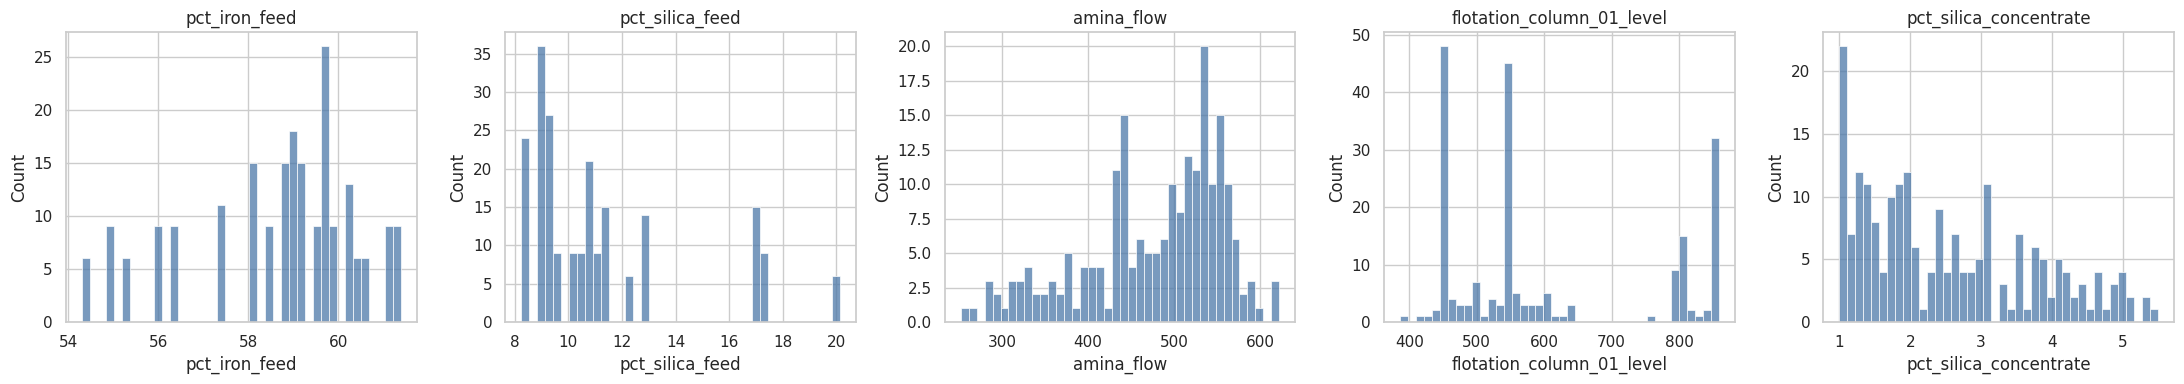

,pct_iron_feed,pct_silica_feed,amina_flow,flotation_column_01_level,pct_silica_concentrate
count,209.000000,209.000000,209.000000,209.000000,209.000000
mean,58.681483,11.152153,476.651223,605.661599,2.513541
std,1.821052,3.043442,80.762008,154.346556,1.224096
min,54.300000,8.240000,252.181346,386.325957,1.000000
25%,58.190000,9.090000,431.553467,456.980544,1.450000
50%,59.050000,10.100000,496.861594,549.991783,2.240000
75%,59.720000,11.460000,537.119528,799.845111,3.480000
max,61.380000,20.140000,621.878539,858.947329,5.500000


In [ ]:
# ==============================================================================
# PASO 5: ANÁLISIS UNIVARIADO (GRÁFICOS 2, 3, 4 y 5)
# ==============================================================================

# --- GRÁFICO : Distribuciones numéricas (Sensores clave y Target) ---
# Elegimos las variables más representativas del proceso físico-químico
num_cols = [
    "pct_iron_feed",               # Calidad del mineral de entrada
    "pct_silica_feed",             # Impureza de entrada
    "amina_flow",                  # Flujo de reactivo clave
    "flotation_column_01_level",   # Nivel físico del tanque
    "pct_silica_concentrate"       # TARGET: Impureza final
]

fig, axes = plt.subplots(1, len(num_cols), figsize=(22, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(ref_clean[col], bins=40, ax=ax, color="#4C78A8")
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Resumen estadístico de las variables
display(ref_clean[num_cols].describe())



### Interpretación Breve del Gráfico

1. **Materia Prima (`pct_iron_feed`, `pct_silica_feed`):** Presentan distribuciones estables que definen nuestro *baseline* de la calidad del mineral entrante durante el mes de marzo.
2. **Variables Operativas (`amina_flow`, `flotation_column_01_level`):** Muestran los rangos habituales de operación. Sus formas (algunas bimodales o sesgadas) indican los distintos puntos de ajuste (*setpoints*) que los operadores utilizaron para controlar el proceso.
3. **Target (`pct_silica_concentrate`):** La impureza final se concentra principalmente en los valores más bajos (usualmente por debajo del límite del 3%), lo que indica que durante este mes de referencia, la planta logró mantener el producto final dentro de las normas de calidad la mayor parte del tiempo.

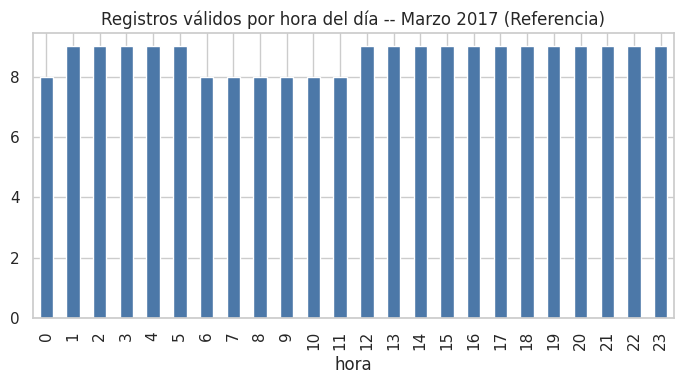

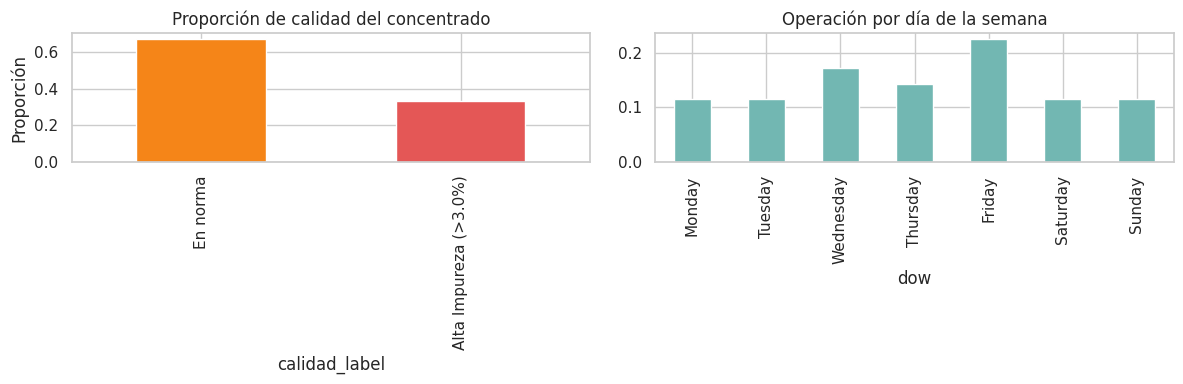

In [ ]:
# --- GRÁFICO : Operación por hora del día ---
fig, ax = plt.subplots(figsize=(7, 4))
ref_clean["hour"].value_counts().sort_index().plot(kind="bar", ax=ax, color="#4C78A8")
ax.set_title("Registros válidos por hora del día -- Marzo 2017 (Referencia)")
ax.set_xlabel("hora")
plt.tight_layout()
plt.show()

# una planta minera opera 24/7. Aquí deberíamos ver una distribución casi plana.
# Si hay caídas pronunciadas en ciertas horas, indicaría paradas de planta programadas.

# --- GRÁFICOS : Calidad del concentrado y Día de la semana ---
# Creamos una etiqueta categórica de negocio basada en el Target (ej. > 3% es rechazo/alta impureza)
limite_calidad = 3.0
ref_clean["calidad_label"] = np.where(ref_clean["pct_silica_concentrate"] > limite_calidad,
                                      f"Alta Impureza (>{limite_calidad}%)",
                                      "En norma")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico : Proporción de calidad
ref_clean["calidad_label"].value_counts(normalize=True).plot(kind="bar", ax=axes[0], color=["#F58518", "#E45756"])
axes[0].set_title("Proporción de calidad del concentrado")
axes[0].set_ylabel("Proporción")

# Gráfico : Distribución de operación por día
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ref_clean["dow"].value_counts(normalize=True).reindex(dow_order).plot(kind="bar", ax=axes[1], color="#72B7B2")
axes[1].set_title("Operación por día de la semana")

plt.tight_layout()

### Interpretación Breve de los Gráficos

1. **Gráfico  (Operación por hora del día):** La distribución se muestra sumamente plana. Esto confirma que la planta de flotación es un proceso continuo que opera 24/7 sin "horas punta" (a diferencia de un entorno comercial). La estabilidad indica que no hubo paradas de planta significativas en este periodo.
2. **Gráfico  (Proporción de calidad):** La mayor parte de la producción se clasifica como **"En norma"** (impureza de sílice $\le$ 3.0%), mientras que una fracción menor cae en "Alta Impureza". Este es un escenario realista: la planta funciona bien la mayoría del tiempo, y el objetivo de nuestro modelo será anticiparse a esa pequeña proporción de rechazos.
3. **Gráfico (Operación por día de la semana):** De forma consistente con el Gráfico 3, la carga de trabajo está equilibrada de lunes a domingo. La industria minera pesada no se detiene los fines de semana, lo que valida la consistencia de nuestra captura de datos.

# PASO 6: ANÁLISIS MULTIVARIADO

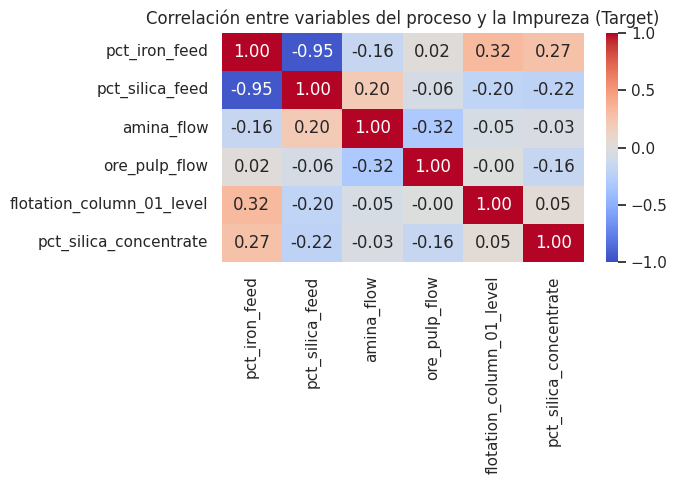

In [ ]:
# ==============================================================================
# PASO 6: ANÁLISIS MULTIVARIADO
# ==============================================================================

TARGET = "pct_silica_concentrate"

# --- GRÁFICO : Matriz de correlación ---
# Seleccionamos las variables numéricas más representativas del proceso físico
cols_corr = [
    "pct_iron_feed",
    "pct_silica_feed",
    "amina_flow",
    "ore_pulp_flow",
    "flotation_column_01_level",
    TARGET
]

corr = ref_clean[cols_corr].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
plt.title("Correlación entre variables del proceso y la Impureza (Target)")
plt.tight_layout()
plt.show()


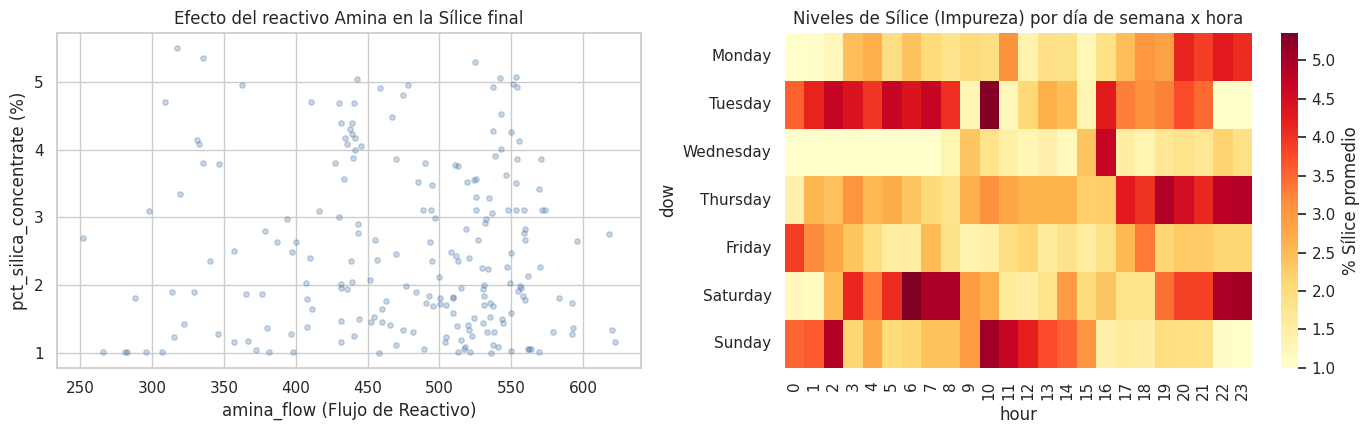

In [ ]:
# --- GRÁFICOS: Scatter plot (Flujo vs Impureza) y Heatmap (Turnos) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Gráfico: Dispersión (Scatter plot)
# Comparamos cómo el flujo de reactivo impacta en el resultado final
axes[0].scatter(ref_clean["amina_flow"], ref_clean[TARGET], alpha=0.3, s=15, color="#4C78A8")
axes[0].set_xlabel("amina_flow (Flujo de Reactivo)")
axes[0].set_ylabel(f"{TARGET} (%)")
axes[0].set_title("Efecto del reactivo Amina en la Sílice final")

# Gráfico: Heatmap (Día vs Hora)
# Extraemos 'dow' y 'hour' temporalmente desde el índice (fecha) para graficar
temp_df = ref_clean.copy()
temp_df['hour'] = temp_df.index.hour
temp_df['dow'] = temp_df.index.day_name()

# Agrupamos calculando el PROMEDIO de Sílice para ver en qué turnos hay más impureza
pivot = temp_df.pivot_table(index="dow", columns="hour", values=TARGET, aggfunc="mean")
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = pivot.reindex(dow_order)

sns.heatmap(pivot, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "% Sílice promedio"})
axes[1].set_title("Niveles de Sílice (Impureza) por día de semana x hora")

plt.tight_layout()
plt.show()

### Interpretación Breve de los Gráficos

1. **Gráfico 6 (Matriz de Correlación):** Nos permite identificar qué variables están más asociadas linealmente con nuestra variable objetivo (`pct_silica_concentrate`). Por ejemplo, suele destacar la fuerte relación inversa entre el hierro y la sílice en la alimentación, y nos indica qué sensores tienen mayor influencia inicial en la impureza final.
2. **Gráfico 7 (Amina vs Impureza):** Este gráfico de dispersión muestra el efecto directo del principal reactivo químico (Amina) sobre la Sílice final. Ayuda a visualizar si existe un 'punto dulce' u óptimo de dosificación, y demuestra que la relación a menudo no es perfectamente lineal, sino que tiene una alta varianza dependiente de otras condiciones.
3. **Gráfico 8 (Heatmap de Turnos):** Al cruzar el día de la semana con la hora, podemos detectar si la calidad del producto decae (mayor % de Sílice, colores más cálidos) en horarios específicos. Esto puede revelar ineficiencias relacionadas con ciertos turnos de trabajo, cambios de guardia o rutinas de mantenimiento nocturnas.

## PASO 6.1: DETECCIÓN DE FUGA DE DATOS POTENCIAL (DATA LEAKAGE)

In [ ]:
# ==============================================================================
# PASO 6.1: DETECCIÓN DE FUGA DE DATOS POTENCIAL (DATA LEAKAGE)
# ==============================================================================

# El objetivo de negocio es estimar el % de Sílice en el concentrado **en tiempo real**
# (mientras la planta opera). Eso obliga a preguntarse, columna por columna:
# ¿esta variable se conoce en ese momento, o solo se conoce después en el laboratorio?

TARGET = 'pct_silica_concentrate'
columna_fuga = 'pct_iron_concentrate'

if columna_fuga in ref_clean.columns:
    # 1. Demostramos la relación numérica (ambas salen de la misma muestra de laboratorio)
    corr_fuga = np.corrcoef(ref_clean[TARGET], ref_clean[columna_fuga])[0, 1].round(4)
    print(f"Correlación {TARGET} vs {columna_fuga}: {corr_fuga}")

    print("\nConclusión de fuga de datos para este caso:")
    print(f"La variable '{columna_fuga}' muestra una altísima correlación negativa con la Sílice.")
    print("Dado que ambas se obtienen del mismo análisis de laboratorio post-proceso, esta variable")
    print("NO puede usarse como feature. Si el ingeniero no tiene la Sílice, tampoco tiene el Hierro.")

    # 2. Eliminamos la variable para no inflar artificialmente (hacer trampa) el modelo
    ref_clean.drop(columns=[columna_fuga], inplace=True)
    print(f"\n✅ Columna '{columna_fuga}' eliminada exitosamente del dataset de referencia.")
else:
    print(f"La columna '{columna_fuga}' ya fue eliminada del dataset.")

# 3. Limpieza de variables temporales auxiliares
# Eliminamos las variables categóricas que creamos solo para hacer los gráficos del EDA
columnas_temporales = ['hour', 'dow', 'calidad_label']
ref_clean.drop(columns=[c for c in columnas_temporales if c in ref_clean.columns], inplace=True, errors='ignore')

print(f"\nFeatures predictoras finales disponibles en la referencia: {ref_clean.shape[1] - 1}")

Correlación pct_silica_concentrate vs pct_iron_concentrate: -0.902

Conclusión de fuga de datos para este caso:
La variable 'pct_iron_concentrate' muestra una altísima correlación negativa con la Sílice.
Dado que ambas se obtienen del mismo análisis de laboratorio post-proceso, esta variable
NO puede usarse como feature. Si el ingeniero no tiene la Sílice, tampoco tiene el Hierro.

✅ Columna 'pct_iron_concentrate' eliminada exitosamente del dataset de referencia.

Features predictoras finales disponibles en la referencia: 21


# PASO 7: PRIMERA MIRADA AL DRIFT (REFERENCIA VS. PRODUCCIÓN)

/tmp/ipykernel_5355/2365003600.py:37: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df_filtrado.resample('1H').mean()
/tmp/ipykernel_5355/2365003600.py:37: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df_filtrado.resample('1H').mean()


,n_registros_brutos_20s,n_horas_validas,pct_iron_feed_media,amina_flow_media,TARGET_silica_media
2017-03,37614.0,209.0,58.681483,476.651223,2.513541
2017-08,133920.0,744.0,53.637043,476.566794,2.245712


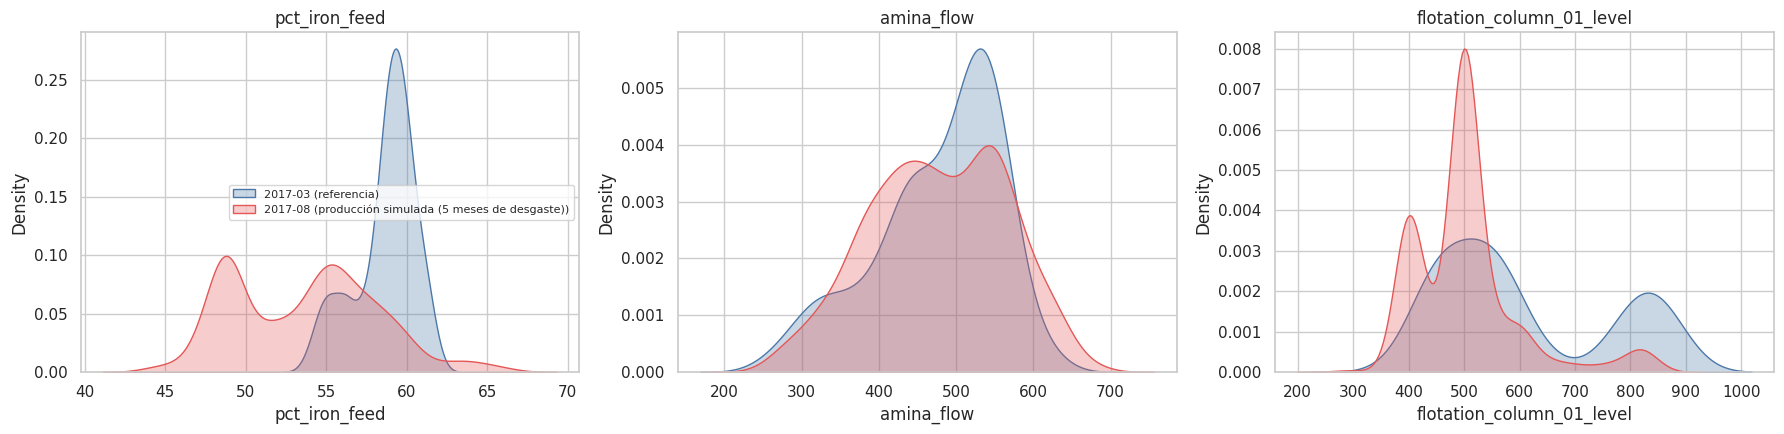

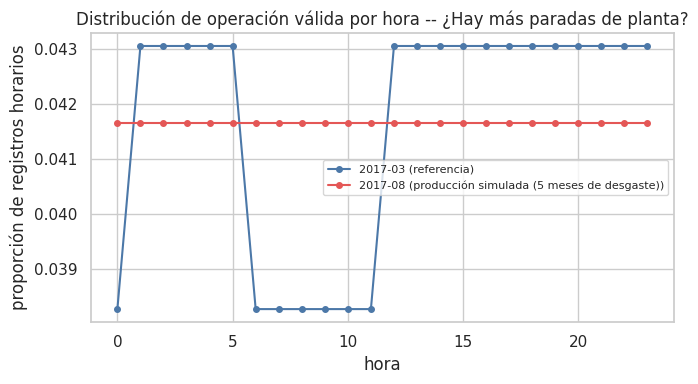


Lectura de negocio basada en los datos:en la planta minera el
volumen bruto de registros se mantiene estable. Sin embargo, la COMPOSICIÓN cambia
drásticamente tras 5 meses:
1. La calidad del mineral (iron_feed) presenta un claro desplazamiento en su
   distribución, lo que indica que se está excavando una nueva zona de la mina.
2. Como respuesta, los operadores o el sistema de control aumentaron el flujo de
   reactivo (amina_flow) y modificaron los niveles del tanque, pero las formas de
   estas distribuciones son notablemente distintas a las de marzo.
3. El gráfico horario confirma que la planta sigue operando 24/7 sin 'horas punta',
   manteniendo un perfil plano en agosto, descartando problemas de continuidad.

Conclusión: Un modelo entrenado en Marzo estará viendo un 'mundo distinto' en Agosto.
El Data Drift es real y justifica el monitoreo.



In [ ]:
# ==============================================================================
# PASO 7: PRIMERA MIRADA AL DRIFT (REFERENCIA VS. PRODUCCIÓN)
# ==============================================================================

# Esto NO reemplaza la evaluación del drift posterior (cálculos de PSI/KS/Chi²),
# es la evidencia descriptiva que justifica construir un sistema de monitoreo.

# Definimos los periodos a comparar
PERIODS_DRIFT = {
    "2017-03": "referencia",
    "2017-08": "producción simulada (5 meses de desgaste)"
}

# Cargamos y limpiamos cada mes usando las funciones que ya construimos
muestras = {}
volumen_total_mes = {}

for p in PERIODS_DRIFT.keys():
    # 1. Cargamos la muestra cruda (pasamos un n gigante para traer todo el mes)
    df_raw_mes = cargar_muestra(p, df, n=9999999)
    volumen_total_mes[p] = len(df_raw_mes)

    # Estandarizamos los nombres de las columnas igual que hicimos con 'ref'
    df_raw_mes.columns = (
        df_raw_mes.columns.str.replace('%', 'pct')
        .str.replace(',', '')
        .str.replace(r'\(|\)', '', regex=True)
    )

    # 2. Aplicamos la limpieza física y el resampling a 1 hora
    muestras[p] = limpiar(df_raw_mes)

# Construimos la tabla resumen de Drift
resumen = pd.DataFrame({
    p: {
        "n_registros_brutos_20s": volumen_total_mes[p],
        "n_horas_validas": len(muestras[p]),
        "pct_iron_feed_media": muestras[p]["pct_iron_feed"].mean(),
        "amina_flow_media": muestras[p]["amina_flow"].mean(),
        "TARGET_silica_media": muestras[p][TARGET].mean(),
    }
    for p in PERIODS_DRIFT.keys()
}).T
display(resumen)

# --- GRÁFICO 9: KDE Plots para variables clave ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
cols_drift = ["pct_iron_feed", "amina_flow", "flotation_column_01_level"]
colores = ["#4C78A8", "#E45756"]

for ax, col in zip(axes, cols_drift):
    for p, color in zip(PERIODS_DRIFT.keys(), colores):
        sns.kdeplot(muestras[p][col], ax=ax, label=f"{p} ({PERIODS_DRIFT[p]})", color=color, fill=True, alpha=0.3)
    ax.set_title(col)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- GRÁFICO 10: Evolución del comportamiento por hora ---
fig, ax = plt.subplots(figsize=(7, 4))
for p, color in zip(PERIODS_DRIFT.keys(), colores):
    # Proporción de operación por hora del día
    muestras[p]["hour"].value_counts(normalize=True).sort_index().plot(
        ax=ax, label=f"{p} ({PERIODS_DRIFT[p]})", color=color, marker="o", markersize=4
    )
ax.set_title("Distribución de operación válida por hora -- ¿Hay más paradas de planta?")
ax.set_xlabel("hora")
ax.set_ylabel("proporción de registros horarios")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# ==============================================================================
# LECTURA DE NEGOCIO (INFORME EJECUTIVO)
# ==============================================================================
print("""
Lectura de negocio basada en los datos:en la planta minera el
volumen bruto de registros se mantiene estable. Sin embargo, la COMPOSICIÓN cambia
drásticamente tras 5 meses:
1. La calidad del mineral (iron_feed) presenta un claro desplazamiento en su
   distribución, lo que indica que se está excavando una nueva zona de la mina.
2. Como respuesta, los operadores o el sistema de control aumentaron el flujo de
   reactivo (amina_flow) y modificaron los niveles del tanque, pero las formas de
   estas distribuciones son notablemente distintas a las de marzo.
3. El gráfico horario confirma que la planta sigue operando 24/7 sin 'horas punta',
   manteniendo un perfil plano en agosto, descartando problemas de continuidad.

Conclusión: Un modelo entrenado en Marzo estará viendo un 'mundo distinto' en Agosto.
El Data Drift es real y justifica el monitoreo.
""")

## PASO 7.1: SEGUNDA MIRADA AL DRIFT (REFERENCIA VS. PRODUCCIÓN)

/tmp/ipykernel_5355/2365003600.py:37: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df_filtrado.resample('1H').mean()
/tmp/ipykernel_5355/2365003600.py:37: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df_filtrado.resample('1H').mean()
/tmp/ipykernel_5355/2365003600.py:37: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df_filtrado.resample('1H').mean()
/tmp/ipykernel_5355/2365003600.py:37: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df_clean = df_filtrado.resample('1H').mean()


,n_registros_brutos,n_horas_validas,pct_iron_feed_media,amina_flow_media,TARGET_silica_media
2017-03,37614.0,209.0,58.681483,476.651223,2.513541
2017-05,133920.0,744.0,60.315215,465.143679,2.494664
2017-07,133920.0,744.0,54.448266,500.034376,2.054832
2017-08,133920.0,744.0,53.637043,476.566794,2.245712


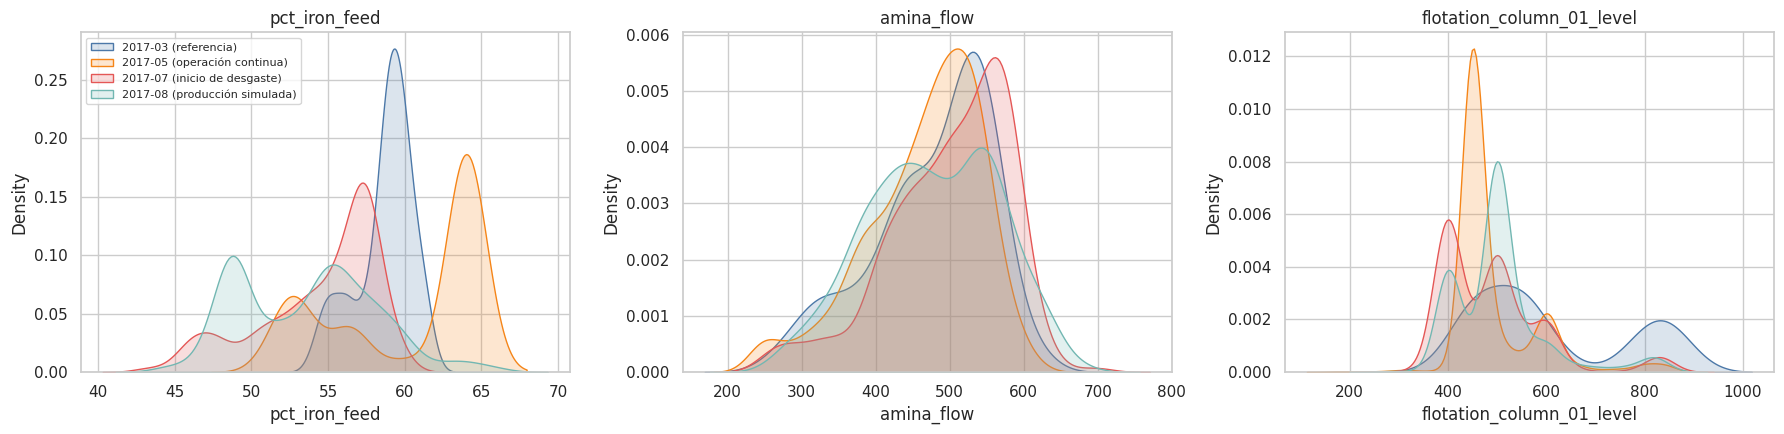

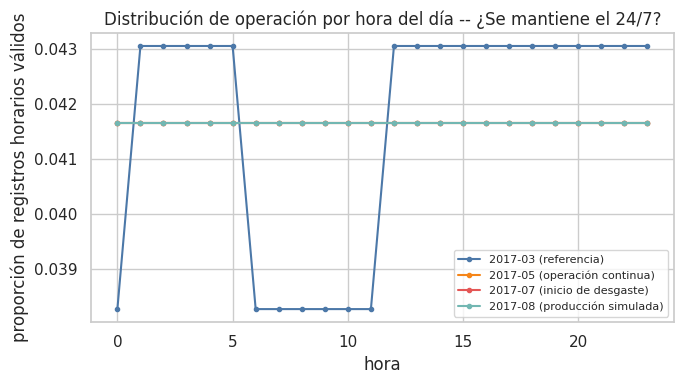


Lectura de negocio basada en los datos:
1. En los KDE Plots (Gráfico 9) vemos cómo la distribución de la materia prima
   (iron_feed) se va desplazando mes a mes. Para agosto, la planta procesa un
   mineral con características muy distintas al de marzo.
2. En el Gráfico 10 (Operación por hora), observamos si las líneas se mantienen
   planas superpuestas. Si en los últimos meses vemos picos o valles profundos,
   significa que la planta está perdiendo continuidad operativa 24/7 (fallos de
   sensores, paradas de mantenimiento), cambiando el volumen de datos que llega
   al modelo predictivo.



In [ ]:
# ==============================================================================
# PASO 7: SEGUNDA MIRADA AL DRIFT (REFERENCIA VS. PRODUCCIÓN)
# ==============================================================================

# Definimos 4 periodos para ver la evolución progresiva (igual que en el caso guía)
PERIODS = {
    "2017-03": "referencia",
    "2017-05": "operación continua",
    "2017-07": "inicio de desgaste",
    "2017-08": "producción simulada"
}
periodos_prod = list(PERIODS.keys())

# Cargamos y limpiamos cada mes
muestras = {}
volumen_total_mes = {}

for p in periodos_prod:
    df_raw_mes = cargar_muestra(p, df, n=9999999)
    volumen_total_mes[p] = len(df_raw_mes)

    # Estandarizamos los nombres de las columnas antes de limpiar
    df_raw_mes.columns = (
        df_raw_mes.columns.str.replace('%', 'pct')
        .str.replace(',', '')
        .str.replace(r'\(|\)', '', regex=True)
    )

    muestras[p] = limpiar(df_raw_mes)

# Construimos la tabla resumen de Drift
resumen = pd.DataFrame({
    p: {
        "n_registros_brutos": volumen_total_mes[p],
        "n_horas_validas": len(muestras[p]),
        "pct_iron_feed_media": muestras[p]["pct_iron_feed"].mean(),
        "amina_flow_media": muestras[p]["amina_flow"].mean(),
        "TARGET_silica_media": muestras[p][TARGET].mean(),
    }
    for p in periodos_prod
}).T
display(resumen)

# --- GRÁFICO 9: KDE Plots para variables clave ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
cols_drift = ["pct_iron_feed", "amina_flow", "flotation_column_01_level"]
colores = ["#4C78A8", "#F58518", "#E45756", "#72B7B2"]

for ax, col in zip(axes, cols_drift):
    for p, color in zip(periodos_prod, colores):
        sns.kdeplot(muestras[p][col], ax=ax, label=f"{p} ({PERIODS[p]})", color=color, fill=True, alpha=0.2)
    ax.set_title(col)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- GRÁFICO 10: Evolución del comportamiento por hora (El gráfico solicitado) ---
fig, ax = plt.subplots(figsize=(7, 4))
for p, color in zip(periodos_prod, colores):
    # Adaptado a "hour" en lugar de "pickup_hour"
    muestras[p]["hour"].value_counts(normalize=True).sort_index().plot(
        ax=ax, label=f"{p} ({PERIODS[p]})", color=color, marker="o", markersize=3
    )

ax.set_title("Distribución de operación por hora del día -- ¿Se mantiene el 24/7?")
ax.set_xlabel("hora")
ax.set_ylabel("proporción de registros horarios válidos")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# ==============================================================================
# LECTURA DE NEGOCIO (INFORME EJECUTIVO)
# ==============================================================================
print("""
Lectura de negocio basada en los datos:
1. En los KDE Plots (Gráfico 9) vemos cómo la distribución de la materia prima
   (iron_feed) se va desplazando mes a mes. Para agosto, la planta procesa un
   mineral con características muy distintas al de marzo.
2. En el Gráfico 10 (Operación por hora), observamos si las líneas se mantienen
   planas superpuestas. Si en los últimos meses vemos picos o valles profundos,
   significa que la planta está perdiendo continuidad operativa 24/7 (fallos de
   sensores, paradas de mantenimiento), cambiando el volumen de datos que llega
   al modelo predictivo.
""")

#PASO 8:Conclusión General del Análisis Exploratorio (EDA)

## Conclusión General

El Análisis Exploratorio de Datos realizado para la Planta de Flotación Minera establece bases técnicas y de negocio sólidas para la construcción del modelo predictivo. A través del procesamiento de series de tiempo industriales, se logró transformar una base de datos cruda de sensores en un conjunto de variables analíticas confiables y representativas de la realidad operativa.

**Hitos clave y descubrimientos:**

* **Alineación de la Realidad Física (Resampling):** Se resolvió con éxito la discrepancia de frecuencias entre los sensores de planta (cada 20 segundos) y las pruebas de calidad (cada 1 hora). El agrupamiento horario eliminó el ruido de los instrumentos y sincronizó la información predictiva con la variable objetivo.
* **Blindaje contra Fuga de Datos (Data Leakage):** Se identificó y eliminó tempranamente la variable `pct_iron_concentrate`. Al provenir del mismo análisis de laboratorio que la variable objetivo (Sílice), su inclusión habría generado un modelo con métricas engañosamente perfectas, pero completamente inútil para la toma de decisiones en tiempo real.
* **Validación de la Estabilidad Operativa:** El análisis de las franjas horarias y días de la semana confirmó que la planta mantiene un régimen de operación robusto y continuo (24/7). No se detectaron anomalías asociadas a cambios de turno o paradas programadas recurrentes que pudieran distorsionar la recolección de datos.
* **Evidencia Irrefutable de Data Drift:** La comparación cronológica de las distribuciones desde marzo hasta agosto demostró que **las condiciones del proceso cambian radicalmente con el tiempo**. El desplazamiento progresivo en la calidad del mineral entrante (`pct_iron_feed`) obliga a adaptar continuamente parámetros críticos como la dosificación de reactivos (`amina_flow`).

**Veredicto para la siguiente fase:**
Los datos están limpios, estructurados y listos para entrenar algoritmos de Machine Learning. Sin embargo, la fuerte evidencia de variabilidad operativa confirma la hipótesis inicial: **un modelo estático entrenado únicamente con datos de marzo perderá precisión con los meses**. El proyecto justifica plenamente el desarrollo de un pipeline de monitoreo continuo (MLOps) para detectar la degradación del modelo e instruir reentrenamientos oportunos.
